In [1]:
from get_data.get_data import get_merged_events
from sequences.which_sector import *
from sequences.get_sequences import *
from sequences.get_sequences import get_sequence_location
import pandas as pd
from sequences.analyze_sequences import *

match = 3836312 # Lech vs Korona
def_areas_x = 12
def_areas_y = 8

events_types_to_analize = ['passes', 'carrys', 'ball_receipts', 'ball_recoverys', 'duels', 'dribbles', 'blocks', 'clearances', 
'dispossesseds', 'errors', 'foul_committeds', 'half_ends', 'injury_stoppages', 'interceptions', 'miscontrols', 'shots', 'goal_keepers']

events = get_merged_events(events_types_to_analize, match)

In [2]:
from dataframe_modify.add_positions import add_positions
from dataframe_modify.swap_perspective import swap_y
from dataframe_modify.swap_perspective import generalize_perspective
from dataframe_modify.grid_areas import add_grid_areas
from dataframe_modify.add_context import add_context
from get_data.get_data import get_sb360
from sequences.get_sequences import get_sequences_by_possession
import time

start_time = time.time()
start_team = events['possession_team'][0]
frames = get_sb360(match)
events = add_context(events, frames)
events = add_positions(events)
events = swap_y(events)
events = generalize_perspective(events, start_team)

events = add_grid_areas(events)

sequences = get_sequences_by_possession(events)

In [3]:
len(sequences)

171

In [4]:
corners = get_corners_sequences(sequences)
print(len(corners))

corners_lech = []
corners_korona = []

for i in range(len(corners)):
    df = corners[i]
    if (df['possession_team'] == 'Lech Poznan').any():
        corners_lech.append(df)

    else:
        corners_korona.append(df)
    


12


In [5]:
goals = get_goals_sequences(sequences)

num of goal sequences : 5


In [6]:
# goals[0].to_csv('goals_0.csv')

In [7]:
len(corners_lech)

10

Team: Lech Poznan
1: Joel Vieira Pereira (Pass) <00:06:07.667>
2: João Pedro Reis Amaral (Ball Receipt*) <00:06:08.191>
2: João Pedro Reis Amaral (Pass) <00:06:09.167>
3: Pedro Miguel Braga Rebocho (Ball Receipt*) <00:06:10.423>
3: Pedro Miguel Braga Rebocho (Carry) <00:06:10.423>
3: Pedro Miguel Braga Rebocho (Pass) <00:06:11.609>
4: Joel Vieira Pereira (Ball Receipt*) <00:06:12.639>
4: Joel Vieira Pereira (Carry) <00:06:12.639>
4: Joel Vieira Pereira (Pass) <00:06:13.899>
5: Afonso Gamelas De Pinho Sousa (Ball Receipt*) <00:06:15.137>
5: Afonso Gamelas De Pinho Sousa (Duel) <00:06:15.137>
6: Bartosz Śpiączka (Clearance) <00:06:15.137>
7: Dawid Błanik (Pass) <00:06:17.674>
8: Ronaldo Octavian Andrei Deaconu (Ball Receipt*) <00:06:19.120>
9: Heorhii Tsitaishvili (Ball Recovery) <00:06:19.120>
9: Heorhii Tsitaishvili (Carry) <00:06:19.120>
9: Heorhii Tsitaishvili (Pass) <00:06:20.625>
10: Joel Vieira Pereira (Ball Receipt*) <00:06:21.989>
11: João Pedro Reis Amaral (Injury Stoppage) <00

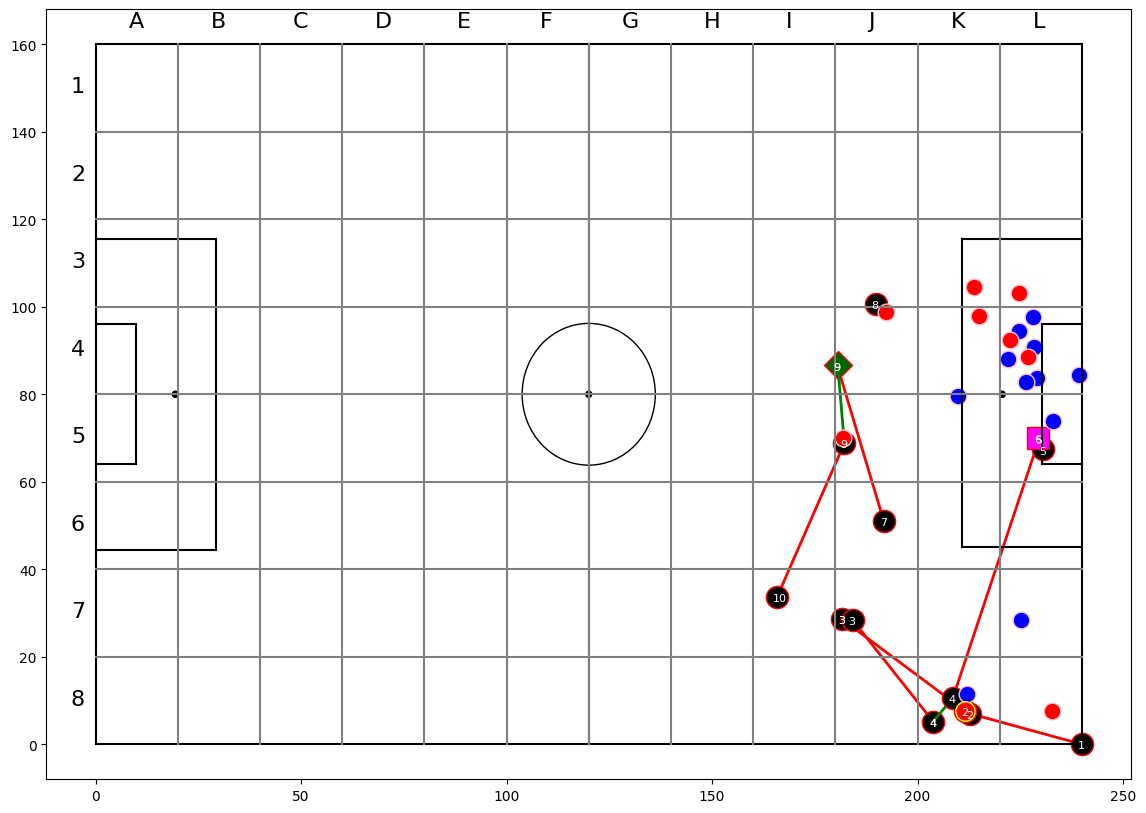

Team: Lech Poznan
1: Pedro Miguel Braga Rebocho (Pass) <00:18:00.781>
2: Mikael Ishak (Ball Receipt*) <00:18:02.021>
2: Mikael Ishak (Duel) <00:18:02.021>
3: Jakub Łukowski (Clearance) <00:18:02.021>


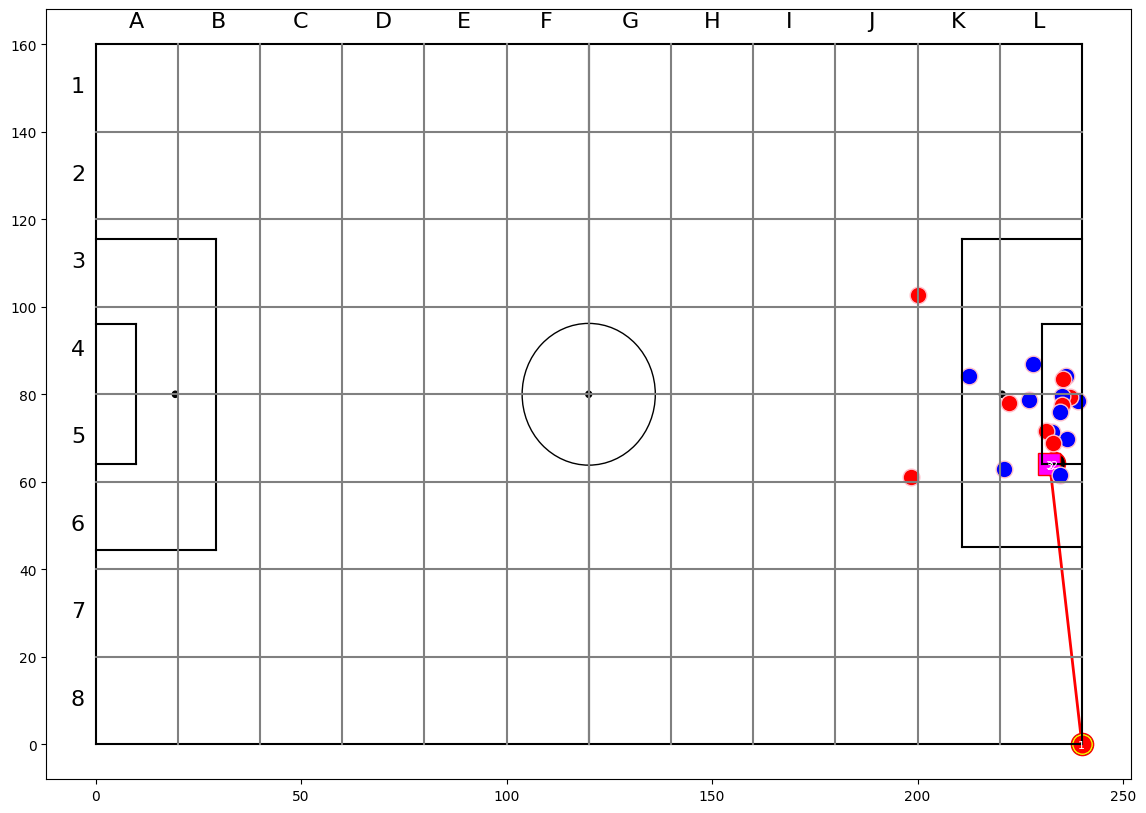

Team: Lech Poznan
1: Pedro Miguel Braga Rebocho (Pass) <00:18:23.475>
2: Filip Dagerstål (Ball Receipt*) <00:18:24.502>
2: Filip Dagerstål (Shot) <00:18:24.542>
3: Jakub Łukowski (Block) <00:18:24.703>
4: Marcel Zapytowski (Goal Keeper) <00:18:24.743>
5: Heorhii Tsitaishvili (Pass) <00:18:26.784>
6: Dawid Błanik (Block) <00:18:27.020>
7: Heorhii Tsitaishvili (Pass) <00:18:28.569>
8: Pedro Miguel Braga Rebocho (Ball Receipt*) <00:18:30.766>
8: Pedro Miguel Braga Rebocho (Carry) <00:18:30.766>
8: Pedro Miguel Braga Rebocho (Pass) <00:18:32.500>
9: João Pedro Reis Amaral (Ball Receipt*) <00:18:34.160>
9: João Pedro Reis Amaral (Foul Committed) <00:18:34.367>


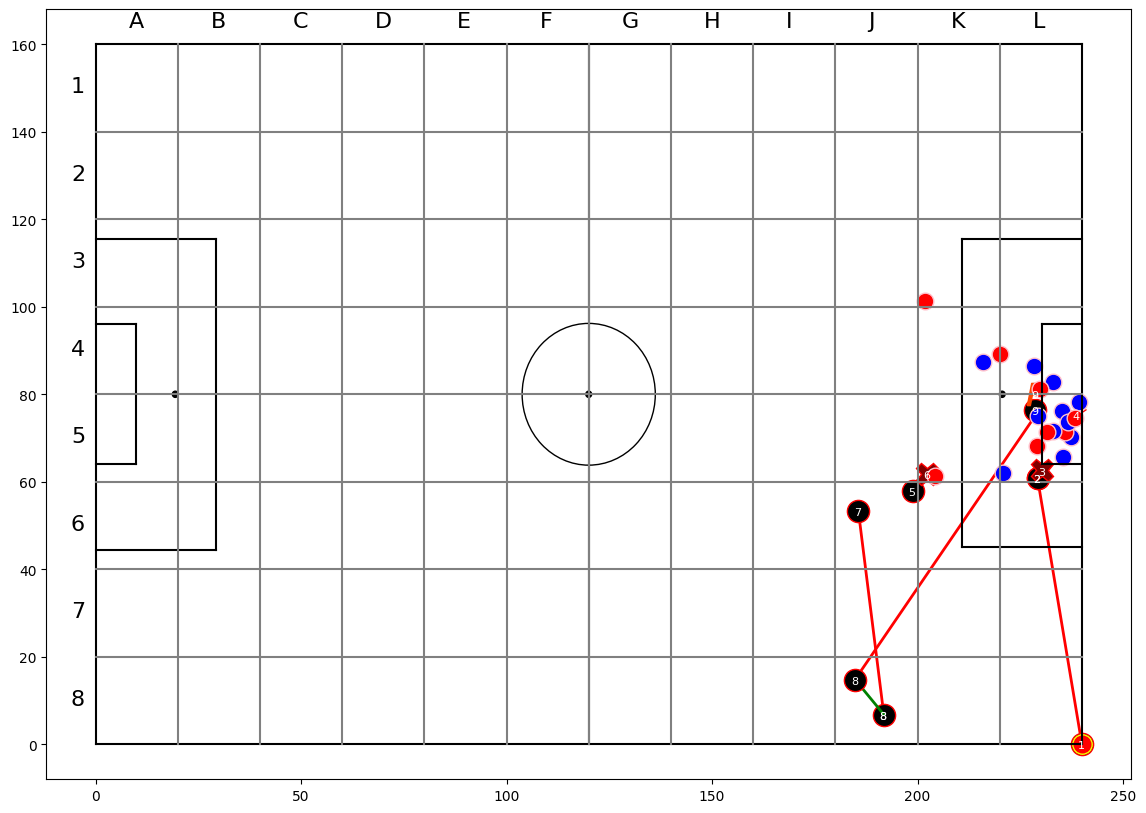

Team: Lech Poznan
1: Pedro Miguel Braga Rebocho (Pass) <00:21:25.454>
2: Jakub Łukowski (Clearance) <00:21:26.448>


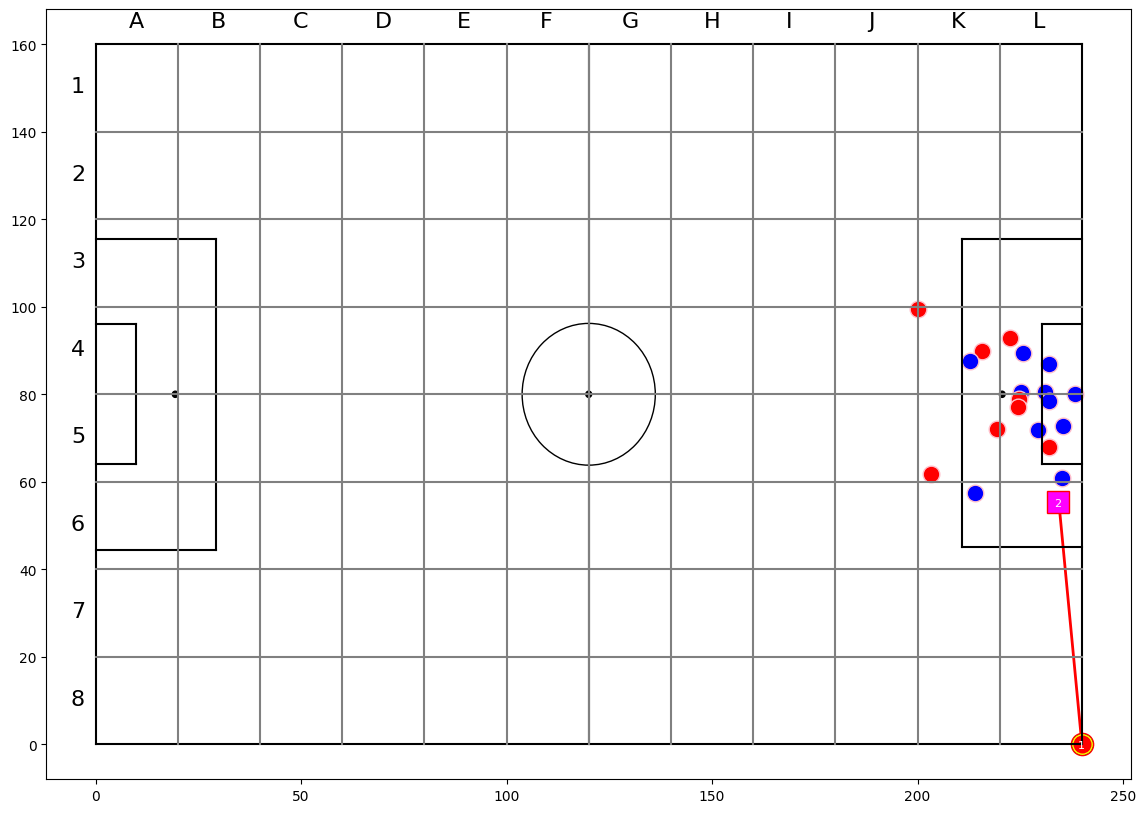

Team: Lech Poznan
1: Nika Kvekveskiri (Pass) <00:22:27.375>
2: Jakub Łukowski (Clearance) <00:22:28.294>
3: Afonso Gamelas De Pinho Sousa (Ball Recovery) <00:22:30.893>
3: Afonso Gamelas De Pinho Sousa (Carry) <00:22:30.893>
3: Afonso Gamelas De Pinho Sousa (Pass) <00:22:33.372>
4: Filip Bednarek (Ball Receipt*) <00:22:37.179>
4: Filip Bednarek (Carry) <00:22:37.179>
4: Filip Bednarek (Pass) <00:22:39.979>
5: Miłosz Trojak (Pass) <00:22:43.235>
6: Adam Deja (Ball Receipt*) <00:22:44.340>
6: Adam Deja (Carry) <00:22:44.340>
6: Adam Deja (Pass) <00:22:46.518>
7: Bartosz Śpiączka (Ball Receipt*) <00:22:48.240>
8: Pedro Miguel Braga Rebocho (Pass) <00:22:48.240>
9: Jesper Karlström (Ball Receipt*) <00:22:48.397>
10: Bartosz Śpiączka (Block) <00:22:48.397>


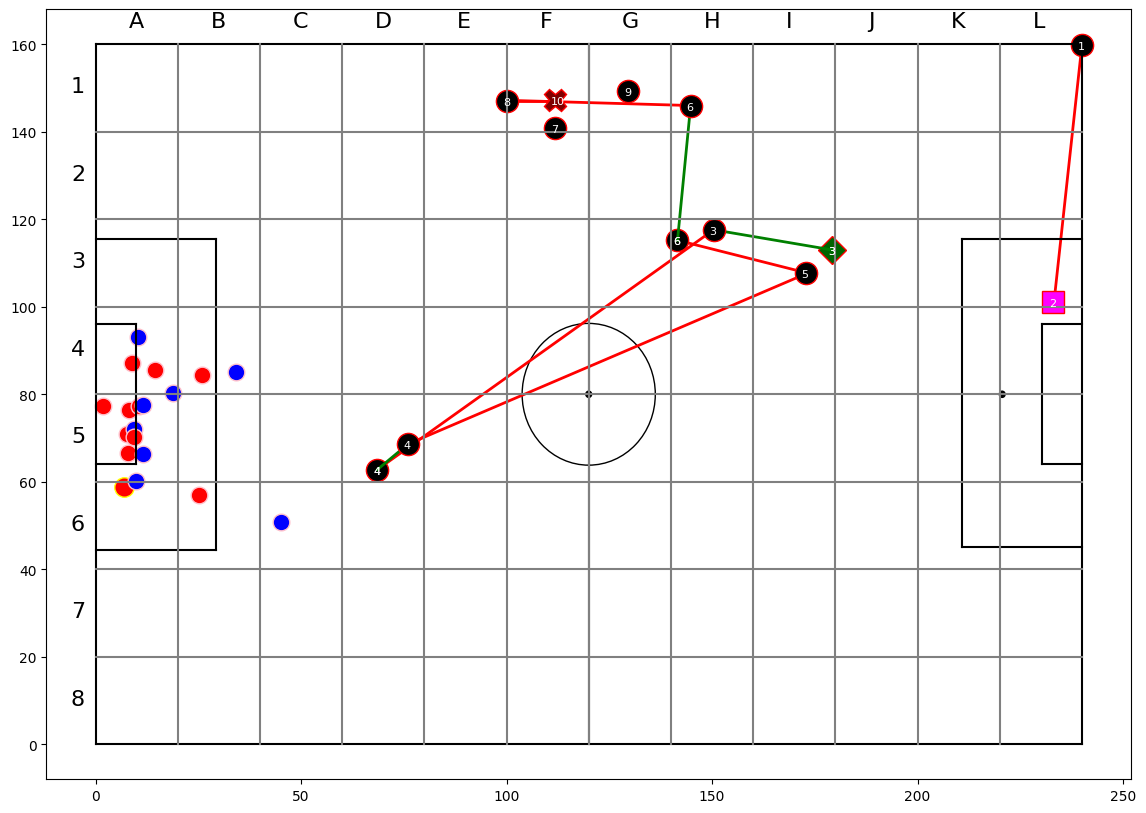

Team: Lech Poznan
1: Joel Vieira Pereira (Pass) <00:26:25.643>
2: Adam Deja (Clearance) <00:26:27.155>
3: Nika Kvekveskiri (Pass) <00:26:30.662>
4: Joel Vieira Pereira (Ball Receipt*) <00:26:32.935>
4: Joel Vieira Pereira (Carry) <00:26:32.935>
4: Joel Vieira Pereira (Pass) <00:26:36.484>
5: Jesper Karlström (Ball Receipt*) <00:26:37.887>
6: Dawid Więckowski (Duel) <00:26:37.928>
7: Jesper Karlström (Pass) <00:26:37.928>
8: Saša Balić (Clearance) <00:26:38.839>
9: João Pedro Reis Amaral (Ball Recovery) <00:26:40.007>
9: João Pedro Reis Amaral (Carry) <00:26:40.007>
9: João Pedro Reis Amaral (Shot) <00:26:41.207>
10: Marcel Zapytowski (Goal Keeper) <00:26:42.110>


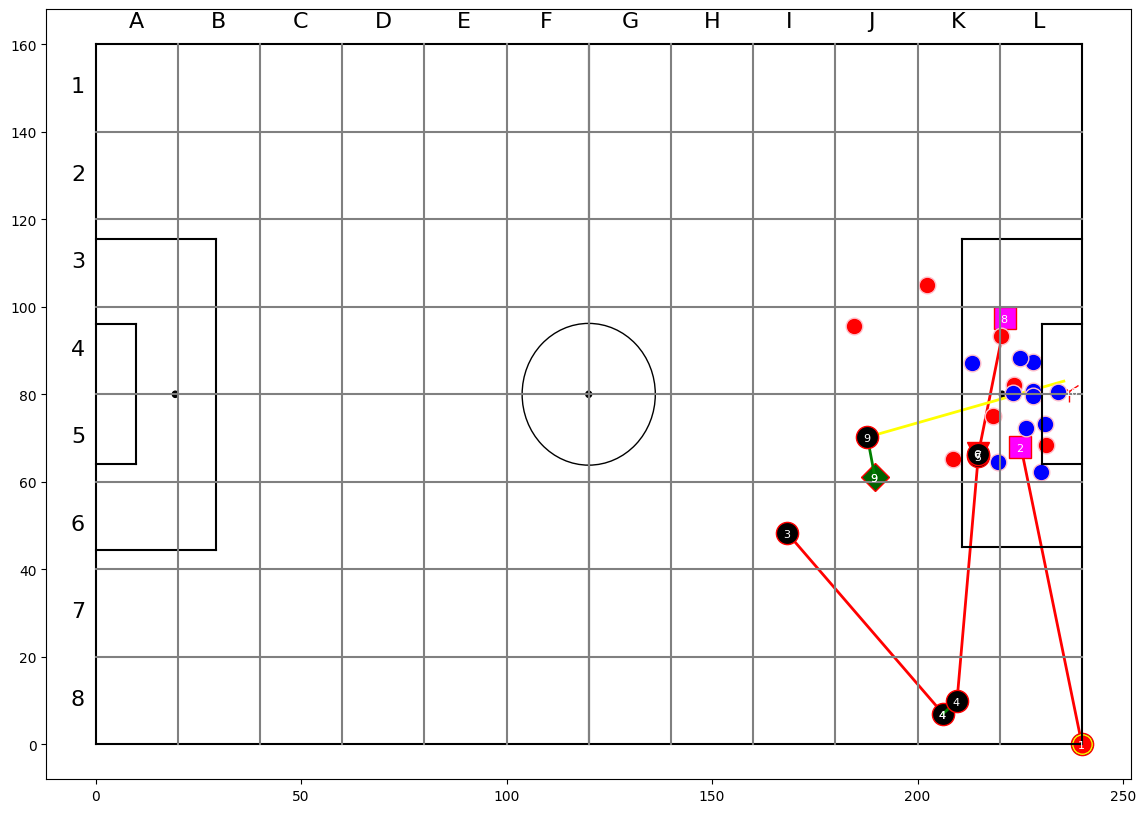

Team: Lech Poznan
1: Nika Kvekveskiri (Pass) <00:27:21.192>
2: Miłosz Trojak (Clearance) <00:27:22.495>
3: Pedro Miguel Braga Rebocho (Ball Recovery) <00:27:24.567>
3: Pedro Miguel Braga Rebocho (Shot) <00:27:24.639>
4: Marcel Zapytowski (Goal Keeper) <00:27:25.418>
5: Heorhii Tsitaishvili (Ball Recovery) <00:27:29.414>
5: Heorhii Tsitaishvili (Carry) <00:27:29.414>
5: Heorhii Tsitaishvili (Pass) <00:27:30.428>
6: Ronaldo Octavian Andrei Deaconu (Block) <00:27:30.595>
7: Pedro Miguel Braga Rebocho (Ball Recovery) <00:27:33.692>
7: Pedro Miguel Braga Rebocho (Carry) <00:27:33.692>
7: Pedro Miguel Braga Rebocho (Pass) <00:27:37.634>
8: Nika Kvekveskiri (Ball Receipt*) <00:27:41.657>
8: Nika Kvekveskiri (Pass) <00:27:41.657>
9: Saša Balić (Pass) <00:27:45.110>
10: Adam Deja (Ball Receipt*) <00:27:48.103>
10: Adam Deja (Duel) <00:27:48.103>
11: Alan Czerwiński (Pass) <00:27:48.103>


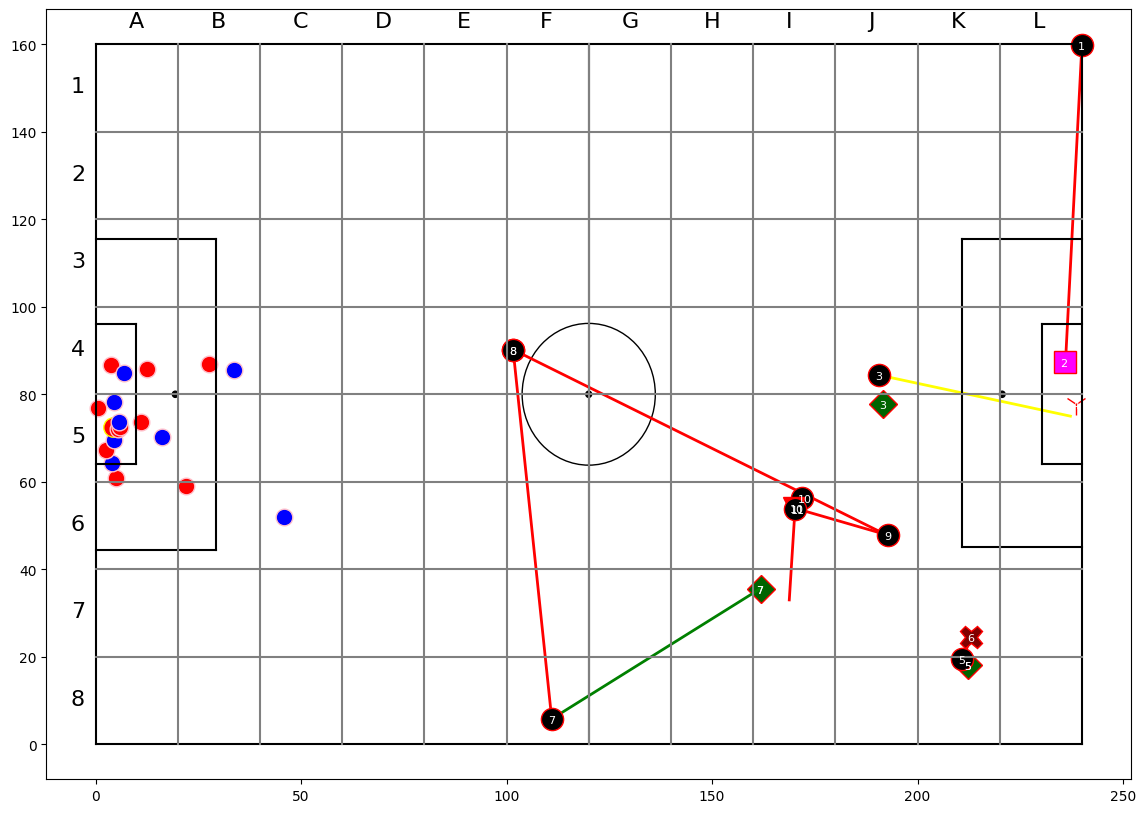

Team: Lech Poznan
1: Pedro Miguel Braga Rebocho (Pass) <00:03:32.504>
2: Afonso Gamelas De Pinho Sousa (Ball Receipt*) <00:03:33.201>
2: Afonso Gamelas De Pinho Sousa (Carry) <00:03:33.201>
2: Afonso Gamelas De Pinho Sousa (Pass) <00:03:34.531>
3: Bartosz Śpiączka (Clearance) <00:03:35.665>
4: Heorhii Tsitaishvili (Pass) <00:03:38.860>
5: Pedro Miguel Braga Rebocho (Ball Receipt*) <00:03:39.910>
5: Pedro Miguel Braga Rebocho (Carry) <00:03:39.910>
5: Pedro Miguel Braga Rebocho (Pass) <00:03:40.450>
6: João Pedro Reis Amaral (Ball Receipt*) <00:03:41.033>
6: João Pedro Reis Amaral (Carry) <00:03:41.033>
6: João Pedro Reis Amaral (Pass) <00:03:41.073>
7: Pedro Miguel Braga Rebocho (Ball Receipt*) <00:03:41.865>
7: Pedro Miguel Braga Rebocho (Carry) <00:03:41.865>
7: Pedro Miguel Braga Rebocho (Pass) <00:03:43.193>
8: Jesper Karlström (Ball Receipt*) <00:03:43.993>


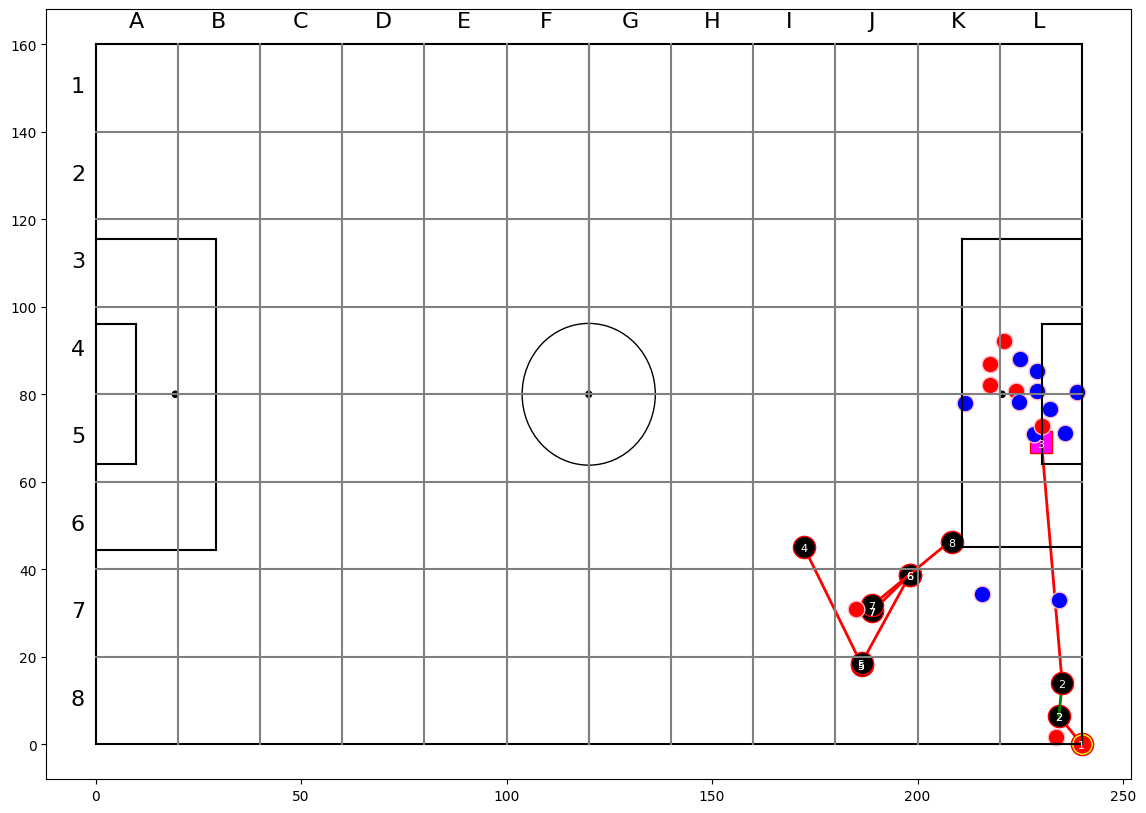

Team: Lech Poznan
1: Joel Vieira Pereira (Pass) <00:20:20.200>
2: Pedro Miguel Braga Rebocho (Ball Receipt*) <00:20:21.372>
2: Pedro Miguel Braga Rebocho (Carry) <00:20:21.372>
2: Pedro Miguel Braga Rebocho (Pass) <00:20:22.295>
3: Afonso Gamelas De Pinho Sousa (Ball Receipt*) <00:20:23.483>
3: Afonso Gamelas De Pinho Sousa (Carry) <00:20:23.483>
3: Afonso Gamelas De Pinho Sousa (Pass) <00:20:25.145>
4: Alan Czerwiński (Ball Receipt*) <00:20:27.278>
5: Saša Balić (Clearance) <00:20:27.278>
6: Mikael Ishak (Pass) <00:20:29.215>
7: João Pedro Reis Amaral (Ball Receipt*) <00:20:30.547>


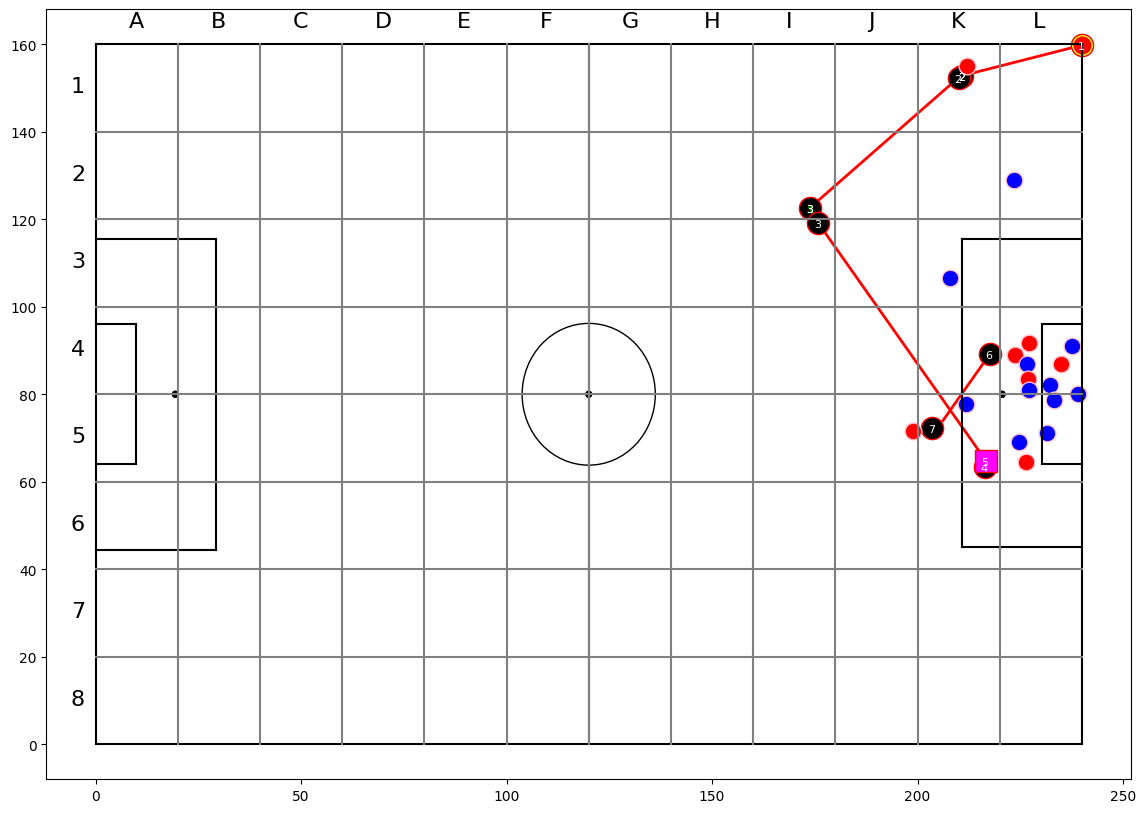

Team: Lech Poznan
1: Alan Czerwiński (Pass) <00:46:27.447>
2: Saša Balić (Clearance) <00:46:29.981>
3: Pedro Miguel Braga Rebocho (Ball Recovery) <00:46:31.453>
3: Pedro Miguel Braga Rebocho (Carry) <00:46:31.453>
3: Pedro Miguel Braga Rebocho (Pass) <00:46:33.838>
4: Radosław Murawski (Ball Receipt*) <00:46:35.486>
4: Radosław Murawski (Carry) <00:46:35.486>
4: Radosław Murawski (Pass) <00:46:36.033>
5: Filip Szymczak (Ball Receipt*) <00:46:36.975>
5: Filip Szymczak (Carry) <00:46:36.975>
5: Filip Szymczak (Shot) <00:46:40.626>
6: Marcel Zapytowski (Goal Keeper) <00:46:41.480>
7: Yevgeny Schikavko (Clearance) <00:46:42.629>


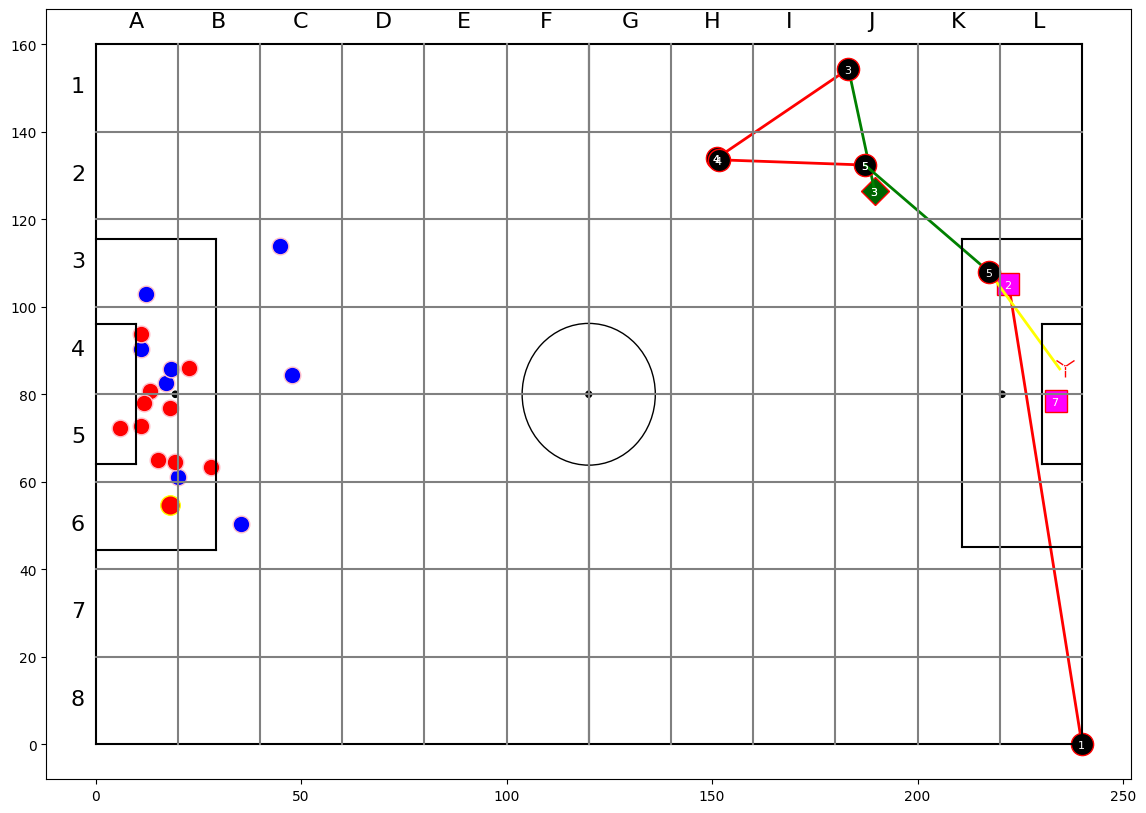

In [8]:
from draw.draw_sequences import draw_events_sequence

start_team ='Lech Poznań'

for i in range(len(corners_lech)):
    draw_events_sequence(corners_lech[i], start_team, 12, 8, scale=2,  first_event_360=True)

In [9]:
corners_lech[6].to_csv('seq.csv')

In [10]:
len(corners_lech)

10

In [11]:
corners_lech[0].to_csv('corners_tst.csv')

In [12]:
get_sequence_by_time(corners_lech, 1, 50, 0)

Exception in get_sequence_by_time! Bad timestamp probably!


In [13]:
seq = get_sequence_by_time(sequences, period=2, minute=46, second=40)
seq.to_csv('goal_amaral.csv')


seq id: 89


Team: Korona Kielce
1: Ronaldo Octavian Andrei Deaconu (Pass) <00:25:01.051>
2: Piotr Malarczyk (Ball Receipt*) <00:25:02.486>
3: Alan Czerwiński (Duel) <00:25:02.486>
4: Piotr Malarczyk (Shot) <00:25:02.486>
5: Filip Bednarek (Goal Keeper) <00:25:03.483>


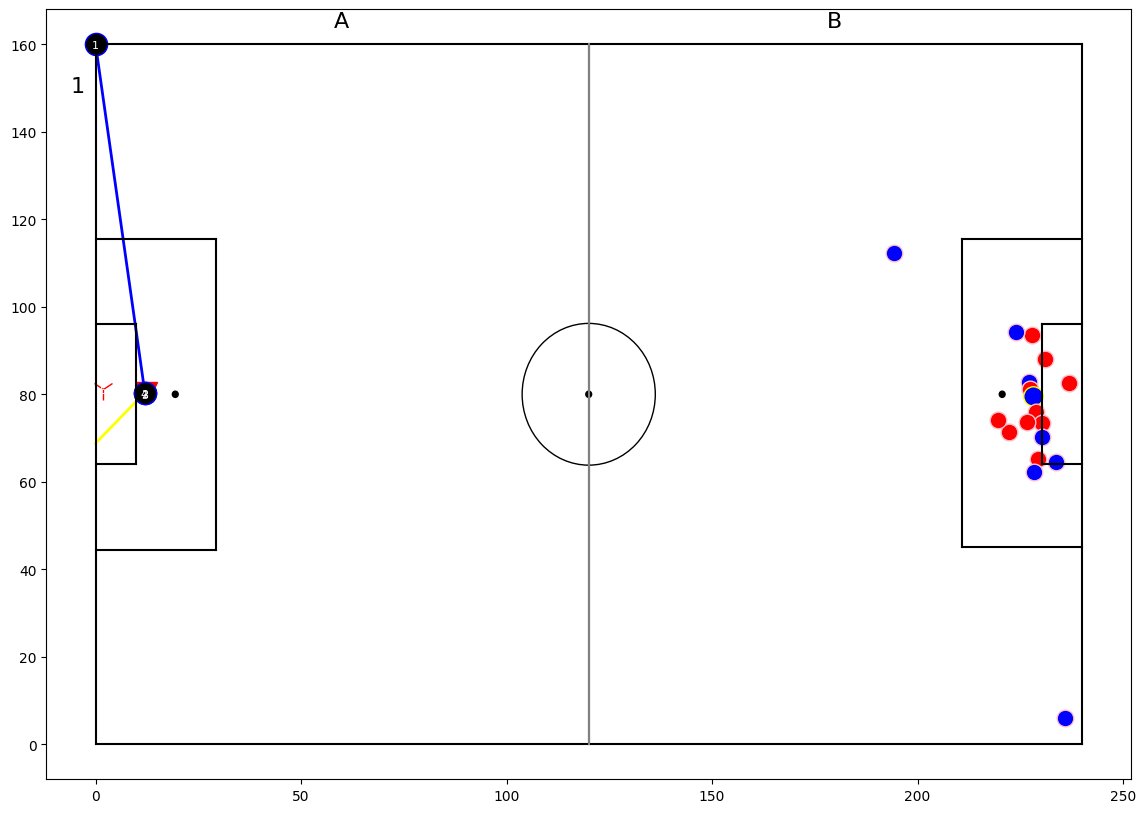

Team: Korona Kielce
1: Ronaldo Octavian Andrei Deaconu (Pass) <00:29:21.447>
2: João Pedro Reis Amaral (Clearance) <00:29:22.520>
3: Afonso Gamelas De Pinho Sousa (Foul Committed) <00:29:23.724>


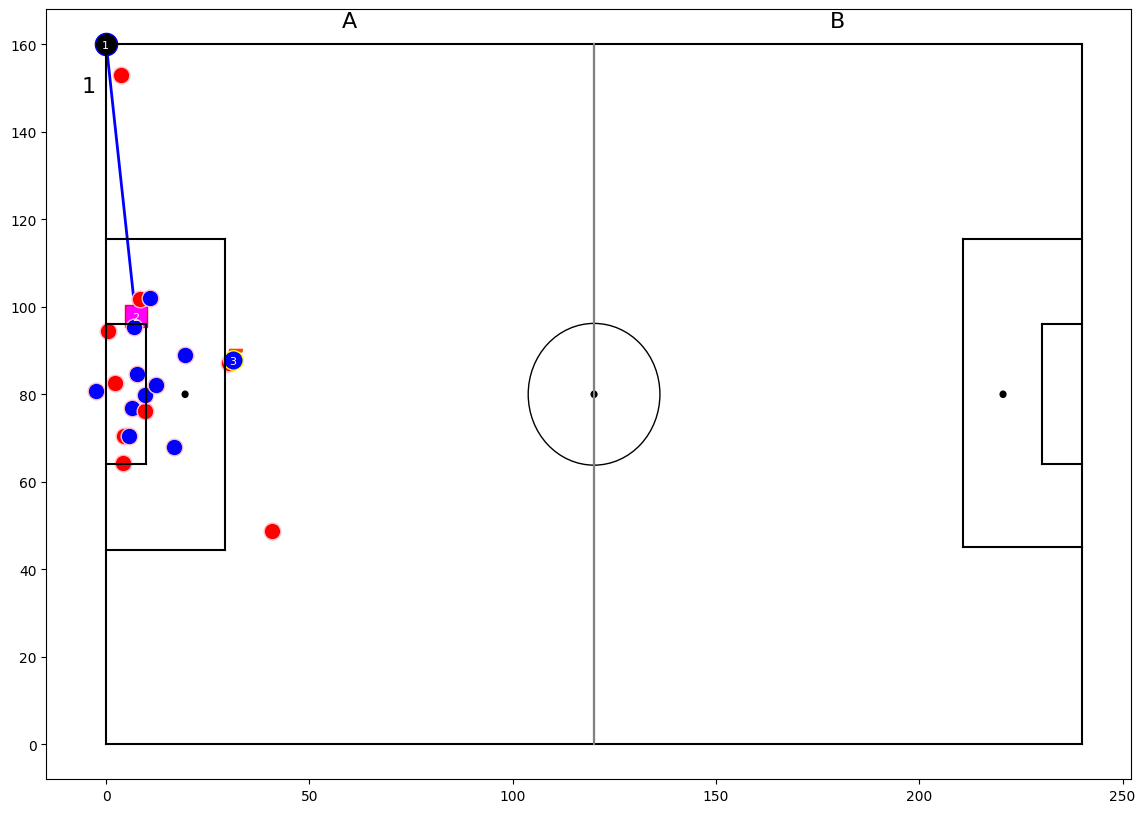

In [14]:
start_team ='Korona Kielce'

for i in range(len(corners_korona)):
    draw_events_sequence(corners_korona[i], start_team, 2, 1, scale=2)

corners_korona[0].to_csv('korona_gol.csv')